# Circuit Library

**Course**: Quantum Computing Laboratory
**Version**: 2.2 (Qiskit 2.2 Compatible)
---

## 📚 Overview

Qiskit's circuit library provides pre-built quantum circuits.

### Categories:
- Standard gates
- Boolean logic
- Arithmetic
- State preparation
- Algorithmic components

In [1]:
from qiskit import QuantumCircuit, transpile        # transpile(circuit, basis_gates=...): rewrite a circuit in a given gate set
from qiskit.circuit.library import (               # ready-made circuits and gates (parentheses let an import span several lines)
    QFT, GroverOperator,                           # Quantum Fourier Transform; Grover iteration (oracle + diffuser)
    ZZFeatureMap, RealAmplitudes,                  # QML: data-encoding feature map; variational ansatz
    EfficientSU2, TwoLocal,                        # more variational ansätze (not used below, try them)
    MCXGate, MCXVChain                             # multi-controlled X; MCX with ancilla qubits
)
import numpy as np                                 # numerics: np.pi, arrays
import matplotlib.pyplot as plt                    # plotting
from IPython.display import display                      # show a figure (e.g. a circuit drawing) from the middle of a cell
def draw(qc, fold=-1, **kw): return qc.draw("mpl", style="clifford", fold=fold, **kw)   # every circuit picture: matplotlib drawer; fold=-1 = one long row, fold=N wraps after N columns

print('✓ Imports successful')


✓ Imports successful


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `from qiskit.circuit.library import (...)` | the circuit library: tested building blocks, so we do not rebuild a QFT or a Grover diffuser by hand |
| `QFT`, `GroverOperator`, `ZZFeatureMap`, `RealAmplitudes` | the class-based API used by the author; Qiskit 2.x prefers the functions/gates `QFTGate`, `grover_operator`, `zz_feature_map`, `real_amplitudes` (same circuits) and prints a DeprecationWarning for the classes |
| `transpile(..., basis_gates=["u", "cx"])` | used below to count what a library block costs in elementary gates |
| `draw(qc)` + `display(...)` | our helper around `qc.draw("mpl")`; `display()` shows a figure from the middle of a cell |

</details>


## Quantum Fourier Transform

/tmp/ipykernel_739046/3467831077.py:2: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qft = QFT(3)                                       # a 3-qubit QFT circuit (a library object that behaves like a QuantumCircuit)


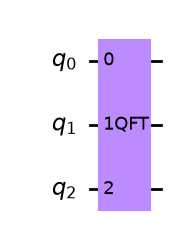

↑ QFT(3) as a single block: the library hides its internal gates


In [2]:
# QFT for 3 qubits
qft = QFT(3)                                       # a 3-qubit QFT circuit (a library object that behaves like a QuantumCircuit)
display(draw(qft)); print("↑ QFT(3) as a single block: the library hides its internal gates")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QFT(3)` | the Quantum Fourier Transform on 3 qubits: \|j⟩ → (1/√8) Σₖ e^{2πi jk/8} \|k⟩ |
| one box | library circuits are drawn as a single instruction until they are decomposed |

</details>


QFT circuit:


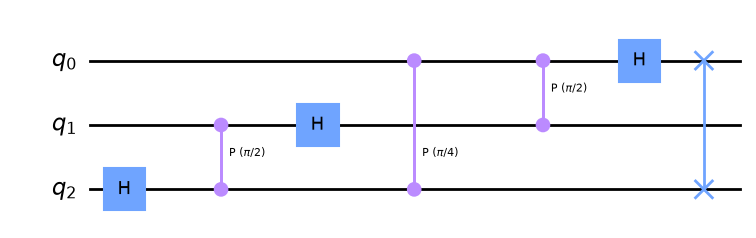

↑ inside the QFT: Hadamards, controlled phases π/2 and π/4, one swap — {'h': 3, 'cp': 3, 'swap': 1}


In [3]:
print('QFT circuit:')
qft_dec = qft.decompose()                          # expand one level: the H, controlled-phase and swap gates
display(draw(qft_dec)); print(f"↑ inside the QFT: Hadamards, controlled phases π/2 and π/4, one swap — {dict(qft_dec.count_ops())}")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `qft.decompose()` | replace the block by its definition (one level) |
| `cp(π/2)`, `cp(π/4)` | controlled phases between qubit pairs; the angle halves as the distance between the qubits grows |
| `swap` | the QFT reverses the qubit order; the swap restores it |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**The QFT on 3 qubits.** For $N = 2^3 = 8$, $\;\mathrm{QFT}\,|j\rangle = \frac{1}{\sqrt8}\sum_{k=0}^{7} e^{2\pi i\, jk/8}|k\rangle$. It factorises into a product state,

$$\mathrm{QFT}\,|j\rangle = \tfrac{1}{\sqrt8}\big(|0\rangle + e^{2\pi i\,0.j_0}|1\rangle\big)\big(|0\rangle + e^{2\pi i\,0.j_1j_0}|1\rangle\big)\big(|0\rangle + e^{2\pi i\,0.j_2j_1j_0}|1\rangle\big),$$

with binary fractions $0.j_1j_0 = j_1/2 + j_0/4$: each factor needs one $H$ and one controlled phase per lower bit, $\pi/2$ for the neighbour and $\pi/4$ for the next one. Gate count: $3$ H $+\ 3$ controlled phases $(n(n-1)/2)$ $+\ 1$ swap $(\lfloor n/2\rfloor)$ — the dictionary printed above. Example: $\mathrm{QFT}\,|0\rangle$ is the uniform superposition, every amplitude $1/\sqrt8 = 0.354$.

</details>


## Grover Operator

/tmp/ipykernel_739046/2316395171.py:6: DeprecationWarning: The class ``qiskit.circuit.library.grover_operator.GroverOperator`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use qiskit.circuit.library.grover_operator instead.
  grover_op = GroverOperator(oracle)                 # Q = diffuser · oracle (one Grover iteration)


Grover operator:


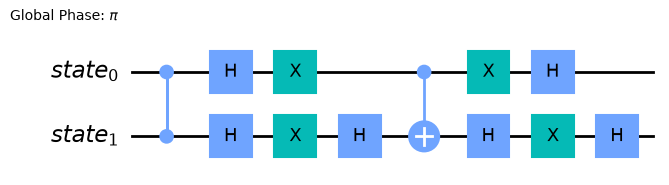

↑ one Grover iteration: the oracle (CZ) and the diffuser (H, X, CZ-type reflection, X, H) — {'h': 6, 'x': 4, 'cz': 1, 'cx': 1}


In [4]:
# Create oracle (mark state |11⟩)
oracle = QuantumCircuit(2)
oracle.cz(0, 1)                                    # CZ flips the sign of |11⟩ only: the "marked" item

# Create Grover operator
grover_op = GroverOperator(oracle)                 # Q = diffuser · oracle (one Grover iteration)
print('Grover operator:')
display(draw(grover_op.decompose())); print(f"↑ one Grover iteration: the oracle (CZ) and the diffuser (H, X, CZ-type reflection, X, H) — {dict(grover_op.decompose().count_ops())}")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `oracle.cz(0, 1)` | a phase oracle: \|11⟩ → −\|11⟩, all other basis states unchanged |
| `GroverOperator(oracle)` | builds Q = (2\|s⟩⟨s\| − I)·O, the reflection about the uniform superposition \|s⟩ after the oracle |
| `.decompose()` | shows the diffuser's gates: H and X layers around a multi-controlled Z |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**One iteration is enough for $N = 4$.** Start from $|s\rangle = H^{\otimes2}|00\rangle = \frac12\sum_x|x\rangle$ and write $|s\rangle = \sin\vartheta\,|w\rangle + \cos\vartheta\,|w^\perp\rangle$, with $|w\rangle = |11\rangle$ and $\sin\vartheta = 1/\sqrt N = 1/2$, i.e. $\vartheta = \pi/6$. Each Grover iteration rotates the state by $2\vartheta$ towards $|w\rangle$, so after $k$ iterations

$$P(w) = \sin^2\big((2k+1)\vartheta\big), \qquad k = 1:\; \sin^2\!\Big(\frac{3\pi}{6}\Big) = \sin^2\frac\pi2 = 1 .$$

One iteration finds the marked item with certainty: the cell below prints $P(11) = 1.000$ on an ideal simulator (a noisy device gives a bit less). The optimal $k \approx \frac{\pi}{4}\sqrt N$ grows only as $\sqrt N$.

</details>


### Running a library circuit

Library blocks are ordinary circuits: put $H^{\otimes 2}$ in front of the Grover operator, measure, and run. The first cell chooses where circuits run (it differs between the IBM and IQM editions); the second is the experiment.


In [5]:
from qiskit_aer import AerSimulator                                            # local classical simulator of a quantum computer
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager   # transpiler: circuit -> backend gates

backend = AerSimulator()                                    # ideal (noise-free) simulator with the same .run interface as a real device
pm = generate_preset_pass_manager(optimization_level=1, backend=backend)   # the transpiler, configured for this backend

def run_circuit(circuit, shots=1024):
    """Transpile + run + counts in one call (used below and in the In-depth analysis)."""
    return backend.run(pm.run(circuit), shots=shots).result().get_counts()   # dict {'bitstring': number of shots}

print(f"run_circuit ready on {backend.name}")


run_circuit ready on aer_simulator


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `AerSimulator()` | a simulator that samples measurement outcomes like a device (ideal gates, finite shots) |
| `pm.run(circuit)` | the transpiler unrolls library blocks (GroverOperator, QFT …) into gates the backend executes |
| `run_circuit(circuit, shots)` | transpile → run → counts; the IQM edition defines the same function with `run_counts`, so the next cells are identical |

</details>


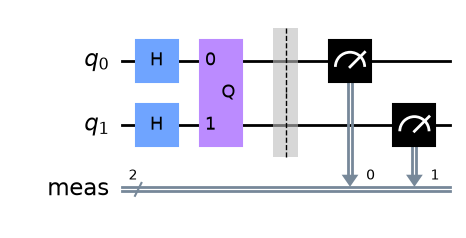

↑ the complete search: H⊗H, one Grover iteration (one box), measurement
counts: {'11': 1024}  ->  P(11) = 1.000


In [6]:
search = QuantumCircuit(2)
search.h([0, 1])                                   # a list of qubits applies the gate to each: |s⟩ = uniform superposition
search.compose(grover_op, inplace=True)            # one Grover iteration
search.measure_all()
display(draw(search)); print("↑ the complete search: H⊗H, one Grover iteration (one box), measurement")

counts = run_circuit(search, shots=1024)
print(f"counts: {counts}  ->  P(11) = {counts.get('11', 0) / 1024:.3f}")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `search.h([0, 1])` | H on both qubits: the uniform superposition the Grover iteration starts from |
| `compose(grover_op, inplace=True)` | append the library block to our circuit |
| `counts.get('11', 0) / 1024` | the measured success probability: 1 in theory (box above) |

</details>


## Feature Maps for QML

ZZ Feature Map:


/tmp/ipykernel_739046/3819461488.py:2: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(feature_dimension=3, reps=2)   # encodes a 3-component data vector x; the block is repeated twice


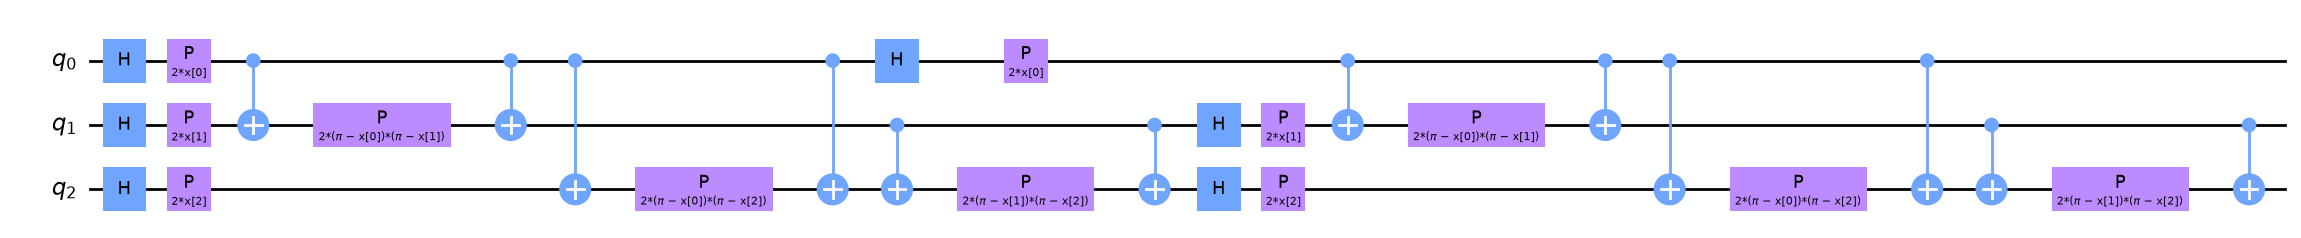

↑ ZZFeatureMap: H on every qubit, P(2x_i) phases, and CX–P–CX pairs for every pair of features; 3 inputs x[0..2], repeated reps=2 times


In [7]:
# ZZ Feature Map
feature_map = ZZFeatureMap(feature_dimension=3, reps=2)   # encodes a 3-component data vector x; the block is repeated twice
print('ZZ Feature Map:')
display(draw(feature_map.decompose())); print(f"↑ ZZFeatureMap: H on every qubit, P(2x_i) phases, and CX–P–CX pairs for every pair of features; {feature_map.num_parameters} inputs x[0..2], repeated reps=2 times")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `ZZFeatureMap(feature_dimension=3, reps=2)` | a quantum-kernel data encoding: the classical vector x becomes the angles of the circuit |
| `P(2·x[i])` | single-feature phases φᵢ(x) = xᵢ |
| `CX – P(2(π−x[i])(π−x[j])) – CX` | a ZZ rotation (the RZZ identity of notebook 02) that couples pairs of features: this makes the kernel hard to simulate classically |

</details>


## Variational Forms

Real Amplitudes ansatz:


/tmp/ipykernel_739046/802549105.py:2: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(num_qubits=3, reps=2)      # RY rotations + CX entanglers, repeated: real amplitudes only


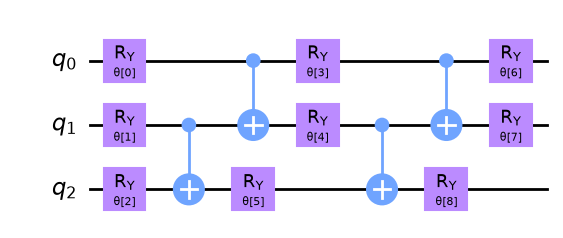

↑ RealAmplitudes: RY layers separated by CNOT entanglers; 9 parameters = 3 qubits × (reps + 1) layers


In [8]:
# Real Amplitudes ansatz
ansatz = RealAmplitudes(num_qubits=3, reps=2)      # RY rotations + CX entanglers, repeated: real amplitudes only
print('Real Amplitudes ansatz:')
display(draw(ansatz.decompose())); print(f"↑ RealAmplitudes: RY layers separated by CNOT entanglers; {ansatz.num_parameters} parameters = 3 qubits × (reps + 1) layers")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `RealAmplitudes(num_qubits=3, reps=2)` | a variational ansatz: (reps + 1) RY layers and reps entangling layers → 3 × 3 = 9 parameters |
| only RY and CX | both have real matrices, so every amplitude of the state stays real — enough for many chemistry and optimisation problems |

</details>


## Multi-Controlled Gates

Multi-controlled X (Toffoli with 3 controls):


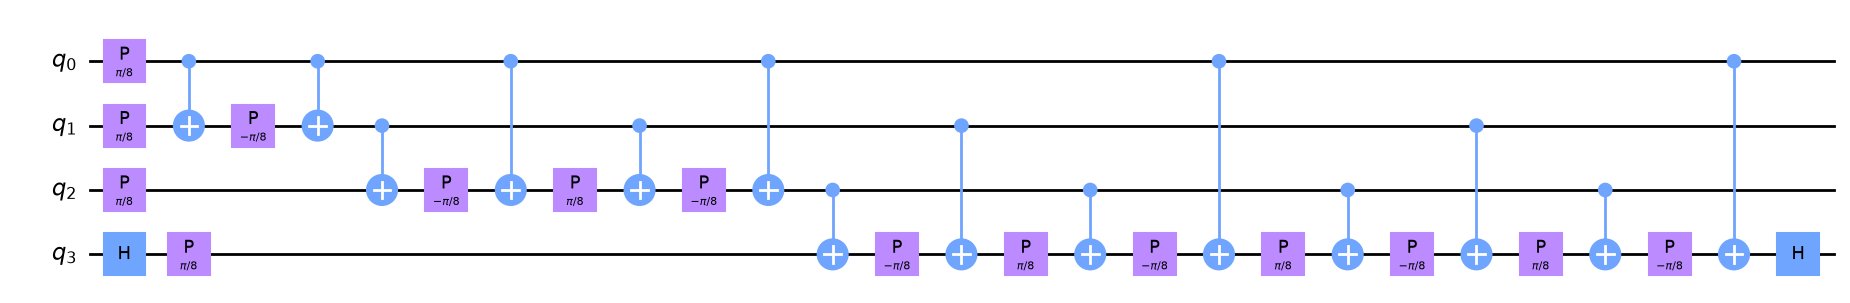

↑ one level down the MCX is still a big block — a 3-control X is not an elementary gate
in elementary gates: {'u': 16, 'cx': 14}, depth 27


In [9]:
# Multi-controlled X gate
mcx = MCXGate(num_ctrl_qubits=3)                   # X on the target only if all 3 controls are |1⟩
qc_mcx = QuantumCircuit(4)
qc_mcx.append(mcx, range(4))                       # qubits 0, 1, 2 = controls, qubit 3 = target
print('Multi-controlled X (Toffoli with 3 controls):')
display(draw(qc_mcx.decompose())); print("↑ one level down the MCX is still a big block — a 3-control X is not an elementary gate")

basic = transpile(qc_mcx, basis_gates=["u", "cx"], optimization_level=3)   # all the way down to one-qubit u + CNOT
print(f"in elementary gates: {dict(basic.count_ops())}, depth {basic.depth()}")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `MCXGate(num_ctrl_qubits=3)` | the 3-controlled NOT (C³X): flips qubit 3 when qubits 0, 1, 2 are all \|1⟩ |
| `qc_mcx.append(mcx, range(4))` | controls first, target last |
| `transpile(..., basis_gates=["u", "cx"])` | the real cost: about 14 CNOTs without ancilla qubits; the count grows quickly with the number of controls (In-depth task 1) |

</details>


## Custom Library Circuits

Using custom gate:


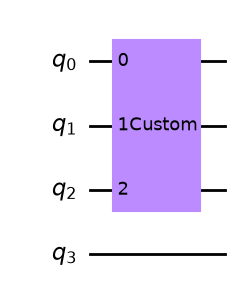

↑ our own 'Custom' block on qubits 0–2: a user-defined gate behaves exactly like a library one


In [10]:
# Create and reuse custom circuit
def my_custom_gate(n_qubits):
    qc = QuantumCircuit(n_qubits, name='Custom')
    qc.h(range(n_qubits))                          # H on every qubit (a range is accepted as a list of qubits)
    for i in range(n_qubits-1):
        qc.cx(i, i+1)
    return qc.to_gate()                            # package it as a gate, like the library does

# Use in circuit
qc_main = QuantumCircuit(4)
qc_main.append(my_custom_gate(3), range(3))        # a 3-qubit instance on qubits 0, 1, 2
print('Using custom gate:')
display(draw(qc_main)); print("↑ our own 'Custom' block on qubits 0–2: a user-defined gate behaves exactly like a library one")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `my_custom_gate(n_qubits)` | a factory that returns a gate of any size — the pattern behind the library classes |
| `qc.to_gate()` | freeze a circuit into a reusable `Gate`; it is drawn as a box named 'Custom' |

</details>


## 🎓 Exercises

1. Create custom oracle using library components
2. Build variational quantum eigensolver circuit
3. Implement custom feature map


## 🔬 In-depth analysis

(Different from the 🎓 Exercises above, which ask you to build new blocks; these measure the cost and behaviour of the library ones.)

1. **The price of many controls.** For $n = 2, \dots, 6$ controls, transpile an `MCXGate(n)` (no ancillas) to the basis `["u", "cx"]` and print the number of CNOTs and the depth. Roughly how does the CNOT count grow with $n$?
2. **The QFT of a basis state.** Apply `QFT(3)` to $|5\rangle$ (`Statevector.from_label("101")`) and check every amplitude against $\frac{1}{\sqrt8}e^{2\pi i\,5k/8}$. What are the magnitudes, and what is the phase step between consecutive $k$?
3. **A bigger search.** On 3 qubits, mark $|111\rangle$ with a CCZ oracle (`h(2); ccx(0, 1, 2); h(2)`) and run $k = 2$ Grover iterations (`grover_op3.power(2)` or two `compose` calls) with `run_circuit`. Compare $P(111)$ with $\sin^2\!\big((2k+1)\vartheta\big)$, $\sin\vartheta = 1/\sqrt8$.

Write your code in the empty cell below; a reference solution follows it. Try first, then compare.


In [11]:
# 🔬 In-depth analysis — your code here



In [12]:
# Reference solution
from qiskit.quantum_info import Statevector

# (1) MCX cost in CNOTs, no ancilla qubits
for n in range(2, 7):
    q = QuantumCircuit(n + 1)
    q.append(MCXGate(n), range(n + 1))
    t = transpile(q, basis_gates=["u", "cx"], optimization_level=3)
    print(f"(1) {n} controls: {t.count_ops().get('cx', 0):4d} CNOTs, depth {t.depth()}")

# (2) QFT|5⟩ against the formula
psi = Statevector.from_label("101").evolve(QFT(3))   # from_label: bitstring (qubit 0 on the right) -> state; evolve: apply a circuit
k = np.arange(8)
formula = np.exp(2j * np.pi * 5 * k / 8) / np.sqrt(8)
print(f"(2) QFT|5> matches the formula: {np.allclose(psi.data, formula)}; magnitudes {np.round(np.abs(psi.data), 3)}, phase step 2π·5/8 = {np.degrees(2*np.pi*5/8):.0f}°")

# (3) 3-qubit Grover, marked state |111⟩, two iterations
oracle3 = QuantumCircuit(3)
oracle3.h(2); oracle3.ccx(0, 1, 2); oracle3.h(2)     # H·X·H = Z on the target: a CCZ, i.e. |111⟩ -> −|111⟩
grover_op3 = GroverOperator(oracle3)
search3 = QuantumCircuit(3)
search3.h(range(3))
search3.compose(grover_op3.power(2), inplace=True)   # .power(2) = the operator applied twice
search3.measure_all()
c3 = run_circuit(search3, shots=2048)
vartheta = np.arcsin(1 / np.sqrt(8))
print(f"(3) P(111) measured = {c3.get('111', 0) / 2048:.3f}, theory sin²(5ϑ) = {np.sin(5 * vartheta)**2:.3f}")


(1) 2 controls:    6 CNOTs, depth 11
(1) 3 controls:   14 CNOTs, depth 27
(1) 4 controls:   36 CNOTs, depth 65


(1) 5 controls:   84 CNOTs, depth 130


(1) 6 controls:  140 CNOTs, depth 192
(2) QFT|5> matches the formula: True; magnitudes [0.354 0.354 0.354 0.354 0.354 0.354 0.354 0.354], phase step 2π·5/8 = 225°
(3) P(111) measured = 0.949, theory sin²(5ϑ) = 0.945


/tmp/ipykernel_739046/3059580890.py:12: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  psi = Statevector.from_label("101").evolve(QFT(3))   # from_label: bitstring (qubit 0 on the right) -> state; evolve: apply a circuit
/tmp/ipykernel_739046/3059580890.py:20: DeprecationWarning: The class ``qiskit.circuit.library.grover_operator.GroverOperator`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use qiskit.circuit.library.grover_operator instead.
  grover_op3 = GroverOperator(oracle3)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `q.append(MCXGate(n), range(n + 1))` | n controls + 1 target; without ancillas the CNOT count grows roughly quadratically in n (6, 14, 36, 84 …) |
| `Statevector.from_label("101").evolve(QFT(3))` | the basis state \|5⟩ (5 = 101₂) pushed through the QFT |
| `np.allclose(a, b)` | element-wise equality up to rounding; all magnitudes are 1/√8 = 0.354, the phase advances by 225° per k |
| `grover_op3.power(2)` | two Grover iterations; for N = 8 the optimum is k = ⌊π/4·√8⌋ = 2, with P = sin²(5ϑ) = 0.945 on an ideal simulator; on a noisy device P(111) is much lower, because two 3-qubit iterations cost dozens of two-qubit gates |

</details>


## 📖 References
- [Qiskit Circuit Library](https://docs.quantum.ibm.com/api/qiskit/circuit_library)
